# Part 1: Forecast accuracy
**Group 3**, UCLA Anderson Time Series Analysis and Forecasting

**Question (RQ1):** how do a classical time series model (AutoARIMA), a machine-learning model (LightGBM) and an AI foundation model (Chronos) compare in forecasting daily grocery demand?

Data: Walmart M5, 4 California stores, 1,437 food items (5,748 daily series). Train 2011-01-29 to 2016-05-22, test the next 28 days (2016-05-23 to 2016-06-19), which no model saw. Seasonal naive ("same weekday last week") is the benchmark.

Run the pipeline in `src/` first (README). This notebook reads its outputs.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

ROOT = Path('..')
PROC, RES, FC, FIG = ROOT/'data/processed', ROOT/'outputs/results', ROOT/'outputs/forecasts', ROOT/'outputs/figures/part1'
FIG.mkdir(parents=True, exist_ok=True)

MODELS = ['AutoARIMA', 'LightGBM', 'Chronos']
BENCH = 'SeasonalNaive'
ALL = MODELS + [BENCH]
LABEL = {'AutoARIMA': 'AutoARIMA', 'LightGBM': 'LightGBM', 'Chronos': 'Chronos', 'SeasonalNaive': 'Seasonal naive'}
# One fixed colour per model in every chart; the benchmark stays grey
COLOR = {'LightGBM': '#2a78d6', 'Chronos': '#eb6834', 'AutoARIMA': '#1baf7a', 'SeasonalNaive': '#8a8984'}
INK, MUTED, GRID = '#0b0b0b', '#8a8984', '#e4e3df'
plt.rcParams.update({
    'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': MUTED, 'axes.labelcolor': INK, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'lines.linewidth': 2, 'legend.frameon': False,
})
def save(fig, name):
    fig.tight_layout(); fig.savefig(FIG/name, bbox_inches='tight')

sales = pd.read_parquet(PROC/'sales_long.parquet')
sales['unique_id'] = sales.unique_id.astype(str)
train = sales[~sales.is_test]
joined = pd.read_parquet(RES/'joined.parquet')
acc = pd.read_csv(RES/'accuracy.csv', index_col=0).loc[ALL]
by_level = pd.read_csv(RES/'accuracy_by_level.csv', index_col=0)[ALL]

# Per-series RMSSE scale (naive one-step error from first sale) and dollar weight, as in M5
tr = train.sort_values(['unique_id', 'd_num'])
started = tr.groupby('unique_id').y.cumsum() > 0
scale = (tr[started].groupby('unique_id').y.diff() ** 2).groupby(tr.loc[started, 'unique_id']).mean().rename('scale')
last28 = tr[tr.d_num > 1941 - 28]
w = (last28.y * last28.sell_price.fillna(0)).groupby(last28.unique_id).sum()
weight = (w / w.sum()).rename('w')
joined = joined.join(scale, on='unique_id').join(weight, on='unique_id')
joined['week'] = (joined.ds - joined.ds.min()).dt.days // 7 + 1
print(f"{joined.unique_id.nunique()} series x {joined.ds.nunique()} test days")

5748 series x 28 test days


## 1. The data

Near-zero spikes = Christmas Day store closures.


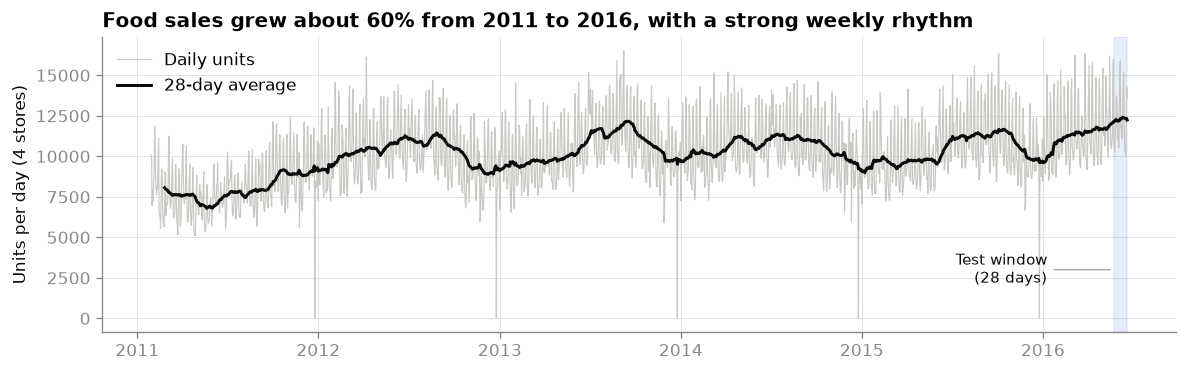

In [2]:
daily = sales.groupby('ds').y.sum()
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(daily.index, daily.values, color='#c9c8c3', linewidth=0.7, label='Daily units')
ax.plot(daily.rolling(28).mean(), color=INK, linewidth=1.8, label='28-day average')
ax.axvspan(daily.index[-28], daily.index[-1], color=COLOR['LightGBM'], alpha=0.12)
ax.annotate('Test window\n(28 days)', (daily.index[-28], 3000), xytext=(-40, 0), textcoords='offset points',
            fontsize=9, color=INK, ha='right', va='center', arrowprops=dict(arrowstyle='-', color=MUTED, lw=0.6))
ax.set_title('Food sales grew about 60% from 2011 to 2016, with a strong weekly rhythm')
ax.set_ylabel('Units per day (4 stores)'); ax.legend(loc='upper left')
save(fig, '01_total_sales.png')
print('Near-zero spikes = Christmas Day store closures.')

SNAP (food-stamp) days lift average sales by 10.2%


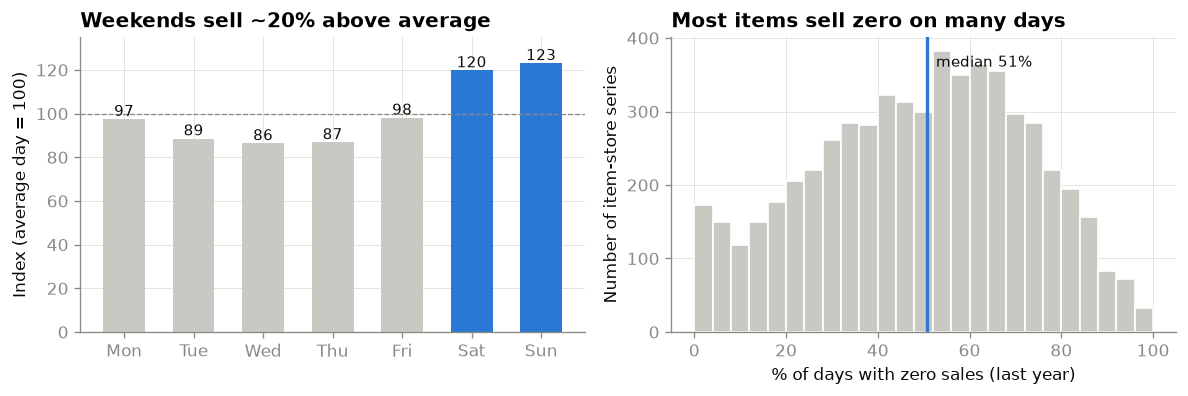

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
wd = train.groupby(train.ds.dt.day_name()).y.mean()
order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
idx = wd[order] / wd.mean() * 100
axes[0].bar([d[:3] for d in order], idx, color=[COLOR['LightGBM'] if d in ('Saturday','Sunday') else '#c9c8c3' for d in order], width=0.6)
axes[0].axhline(100, color=MUTED, linewidth=0.8, linestyle='--')
for x, v in enumerate(idx): axes[0].text(x, v + 1.5, f'{v:.0f}', ha='center', fontsize=9, color=INK)
axes[0].set_ylim(0, 135); axes[0].set_title('Weekends sell ~20% above average'); axes[0].set_ylabel('Index (average day = 100)')

zero_share = train[train.d_num > 1941 - 365].groupby('unique_id').y.apply(lambda s: (s == 0).mean())
axes[1].hist(zero_share * 100, bins=25, color='#c9c8c3', edgecolor='white', linewidth=1)
axes[1].axvline(zero_share.median() * 100, color=COLOR['LightGBM'], linewidth=2)
axes[1].text(zero_share.median() * 100 + 2, axes[1].get_ylim()[1] * 0.9, f'median {zero_share.median():.0%}', color=INK, fontsize=9)
axes[1].set_title('Most items sell zero on many days'); axes[1].set_xlabel('% of days with zero sales (last year)')
axes[1].set_ylabel('Number of item-store series')
save(fig, '02_demand_patterns.png')
snap = train.groupby('snap').y.mean()
print(f"SNAP (food-stamp) days lift average sales by {snap[1]/snap[0]-1:.1%}")

## 2. Overall accuracy
WRMSSE is the official M5 metric: each series' error is scaled by how hard it is to forecast, weighted by its dollar sales, and averaged over six levels (total, store, department, store x department, item, item x store). Below 1 = better than a naive one-day-ahead forecast.

,WRMSSE,MAE,RMSE,Bias (units/day)
AutoARIMA,0.892,1.563,3.226,0.037
LightGBM,0.646,1.547,3.110,-0.022
Chronos,0.949,1.523,3.387,-0.235
Seasonal naive,0.814,1.855,3.729,-0.004


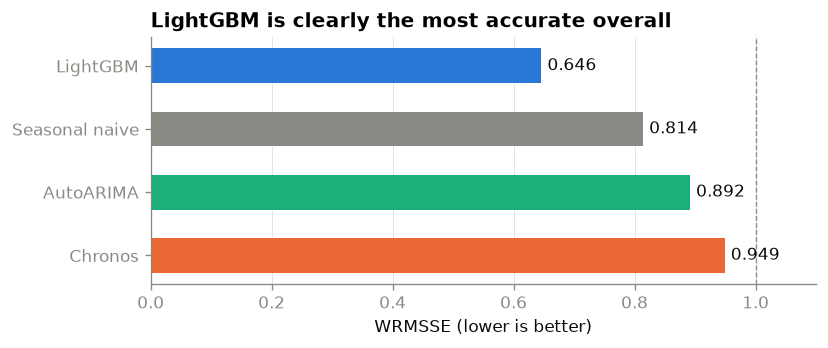

In [4]:
table = acc[['WRMSSE', 'MAE', 'RMSE', 'Bias (units/day)']].rename(index=LABEL)
display(table.round(3))

s = acc.WRMSSE.sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh([LABEL[m] for m in s.index], s.values, color=[COLOR[m] for m in s.index], height=0.55)
for y, (m, v) in enumerate(s.items()):
    ax.text(v + 0.01, y, f'{v:.3f}', va='center', fontsize=10, color=INK)
ax.axvline(1, color=MUTED, linestyle='--', linewidth=0.8)
ax.set_xlim(0, 1.1); ax.grid(axis='y', visible=False)
ax.set_title('LightGBM is clearly the most accurate overall'); ax.set_xlabel('WRMSSE (lower is better)')
save(fig, '03_wrmsse.png')

## 3. Where the models differ: aggregate vs item level

,AutoARIMA,LightGBM,Chronos,Seasonal naive
L1 total,0.790,0.332,0.899,0.511
L2 store,0.813,0.505,0.931,0.598
L3 dept,0.855,0.463,0.931,0.627
L4 store x dept,0.900,0.628,0.969,0.739
L5 item,1.057,1.024,1.042,1.244
L6 item x store,0.936,0.923,0.923,1.167


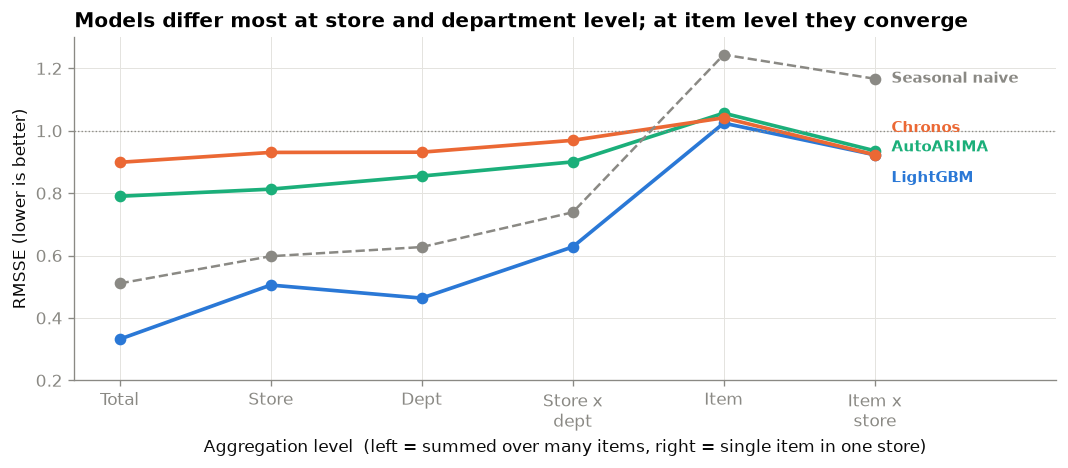

In [5]:
levels = ['L1 total', 'L2 store', 'L3 dept', 'L4 store x dept', 'L5 item', 'L6 item x store']
short = ['Total', 'Store', 'Dept', 'Store x\ndept', 'Item', 'Item x\nstore']
fig, ax = plt.subplots(figsize=(9, 4))
for m in ALL:
    ax.plot(short, by_level.loc[levels, m], color=COLOR[m], marker='o', markersize=6,
            linestyle='--' if m == BENCH else '-', linewidth=1.5 if m == BENCH else 2.2)
    ax.annotate(LABEL[m], (5, by_level.loc[levels[-1], m]), xytext=(10, {'Chronos': 16, 'LightGBM': -14, 'AutoARIMA': 2, 'SeasonalNaive': 0}[m]),
                textcoords='offset points', color=COLOR[m] if m != BENCH else MUTED, fontsize=9, va='center', fontweight='bold')
ax.axhline(1, color=MUTED, linestyle=':', linewidth=0.8)
ax.set_xlim(-0.3, 6.2); ax.set_ylim(0.2, 1.3)
ax.set_title('Models differ most at store and department level; at item level they converge')
ax.set_ylabel('RMSSE (lower is better)'); ax.set_xlabel('Aggregation level  (left = summed over many items, right = single item in one store)')
save(fig, '04_accuracy_by_level.png')
display(by_level.loc[levels].rename(columns=LABEL).round(3))

MAPE of total daily units: {'AutoARIMA': '9.9%', 'LightGBM': '4.1%', 'Chronos': '10.4%', 'Seasonal naive': '5.5%'}


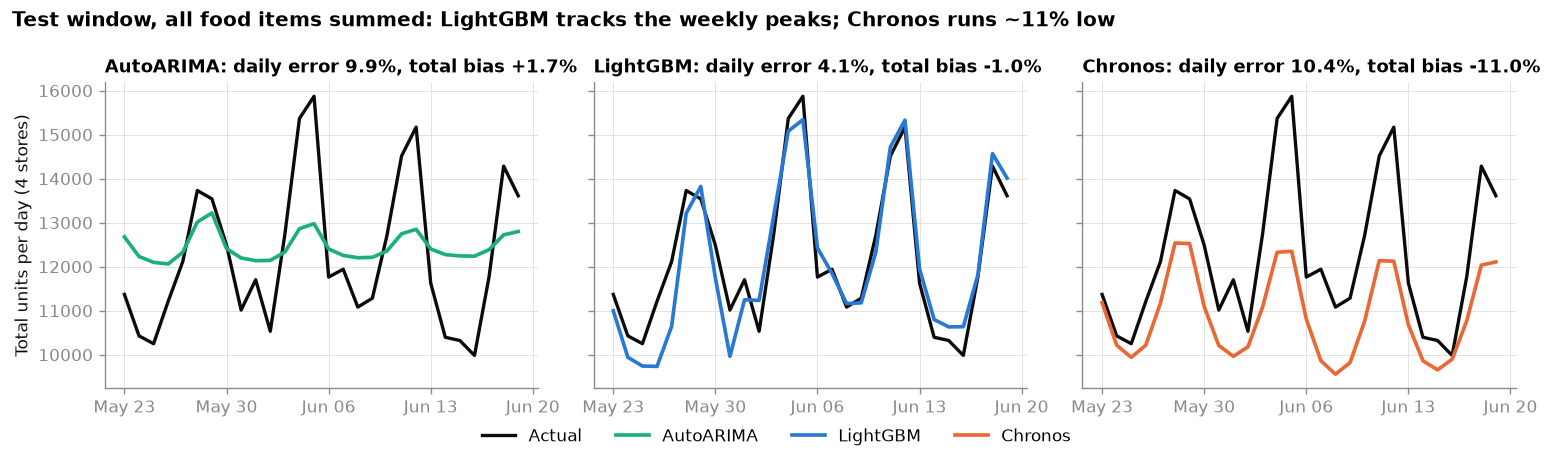

In [6]:
tot = joined.groupby('ds')[['y'] + ALL].sum()
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, m in zip(axes, MODELS):
    mape = ((tot[m] - tot.y).abs() / tot.y).mean()
    bias = tot[m].sum() / tot.y.sum() - 1
    ax.plot(tot.index, tot.y, color=INK, linewidth=2, label='Actual')
    ax.plot(tot.index, tot[m], color=COLOR[m], linewidth=2.2, label=LABEL[m])
    ax.set_title(f'{LABEL[m]}: daily error {mape:.1%}, total bias {bias:+.1%}', fontsize=11)
    ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO)); ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
axes[0].set_ylabel('Total units per day (4 stores)')
handles = [plt.Line2D([], [], color=INK, lw=2)] + [plt.Line2D([], [], color=COLOR[m], lw=2.2) for m in MODELS]
fig.legend(handles, ['Actual'] + [LABEL[m] for m in MODELS], ncol=4, loc='lower center', bbox_to_anchor=(0.5, -0.06))
fig.suptitle('Test window, all food items summed: LightGBM tracks the weekly peaks; Chronos runs ~11% low', x=0.01, ha='left', fontweight='bold', fontsize=12)
save(fig, '05_total_test_window.png')
print('MAPE of total daily units:', {LABEL[m]: f"{((tot[m]-tot.y).abs()/tot.y).mean():.1%}" for m in ALL})

**Why AutoARIMA and Chronos lose at aggregate level.** Each is fitted to one item at a time. For an item that sells 0-2 units a day, the best single-item forecast is nearly flat, so the weekly pattern is lost; summed over 5,748 items, those flat forecasts miss the weekend peaks. Chronos also forecasts slightly low on sparse series, which adds up to an 11% shortfall in total. LightGBM is one model trained on all items at once, so it learns the shared weekly and SNAP patterns.

## 4. At item level, there is no clear winner

,AutoARIMA,LightGBM,Chronos,Seasonal naive
zero_days,,,,
<20%,0.830,0.825,0.820,1.019
20-50%,0.807,0.796,0.803,1.058
50-80%,0.786,0.783,0.785,1.058
>80%,0.899,0.901,0.911,1.163


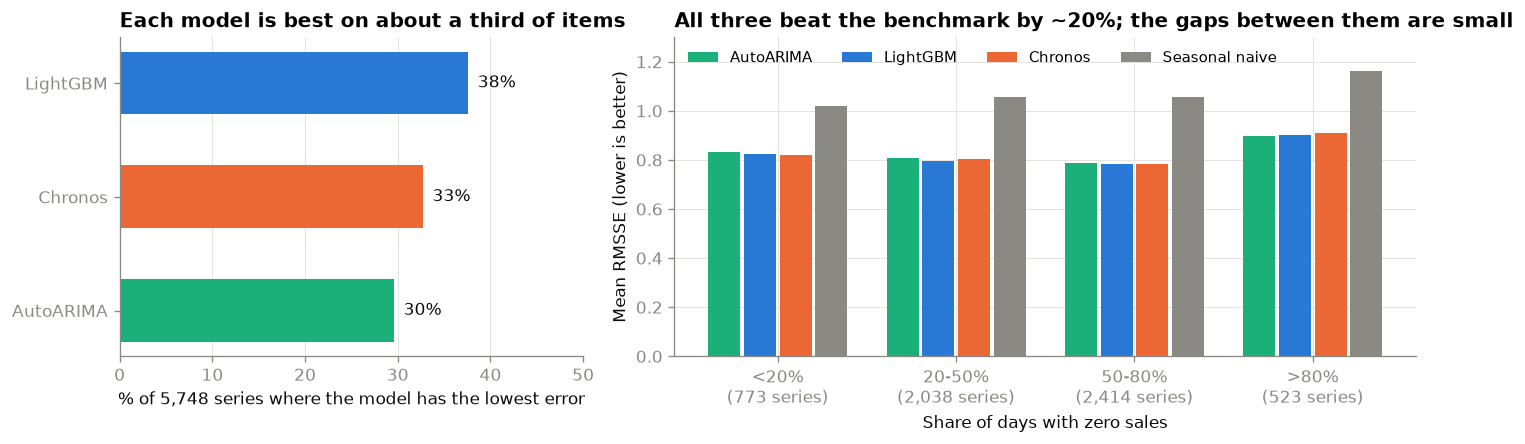

In [7]:
g = joined[joined.scale > 0]
per = g.groupby('unique_id').apply(lambda d: pd.Series({m: np.sqrt(((d[m] - d.y) ** 2).mean() / d.scale.iloc[0]) for m in ALL}), include_groups=False)
best = per[MODELS].idxmin(axis=1).value_counts(normalize=True).reindex(MODELS)

zero = train[train.d_num > 1941 - 365].groupby('unique_id').y.apply(lambda s: (s == 0).mean())
grp = pd.cut(zero, [-0.01, 0.2, 0.5, 0.8, 1.0], labels=['<20%', '20-50%', '50-80%', '>80%']).rename('zero_days')
by_grp = per.join(grp).groupby('zero_days', observed=True)[ALL].mean()
counts = grp.value_counts().reindex(by_grp.index)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={'width_ratios': [1, 1.6]})
b = best.sort_values()
axes[0].barh([LABEL[m] for m in b.index], b.values * 100, color=[COLOR[m] for m in b.index], height=0.55)
for y, v in enumerate(b.values): axes[0].text(v * 100 + 1, y, f'{v:.0%}', va='center', color=INK)
axes[0].set_xlim(0, 50); axes[0].grid(axis='y', visible=False)
axes[0].set_title('Each model is best on about a third of items'); axes[0].set_xlabel('% of 5,748 series where the model has the lowest error')

x = np.arange(len(by_grp)); bw = 0.2
for i, m in enumerate(ALL):
    axes[1].bar(x + (i - 1.5) * bw, by_grp[m], width=bw - 0.02, color=COLOR[m], label=LABEL[m])
axes[1].set_xticks(x, [f'{l}\n({n:,} series)' for l, n in zip(by_grp.index, counts)])
axes[1].set_xlabel('Share of days with zero sales'); axes[1].set_ylabel('Mean RMSSE (lower is better)')
axes[1].set_ylim(0, 1.3); axes[1].legend(ncol=4, loc='upper left', fontsize=9)
axes[1].set_title('All three beat the benchmark by ~20%; the gaps between them are small')
save(fig, '06_item_level.png')
display(by_grp.rename(columns=LABEL).round(3))

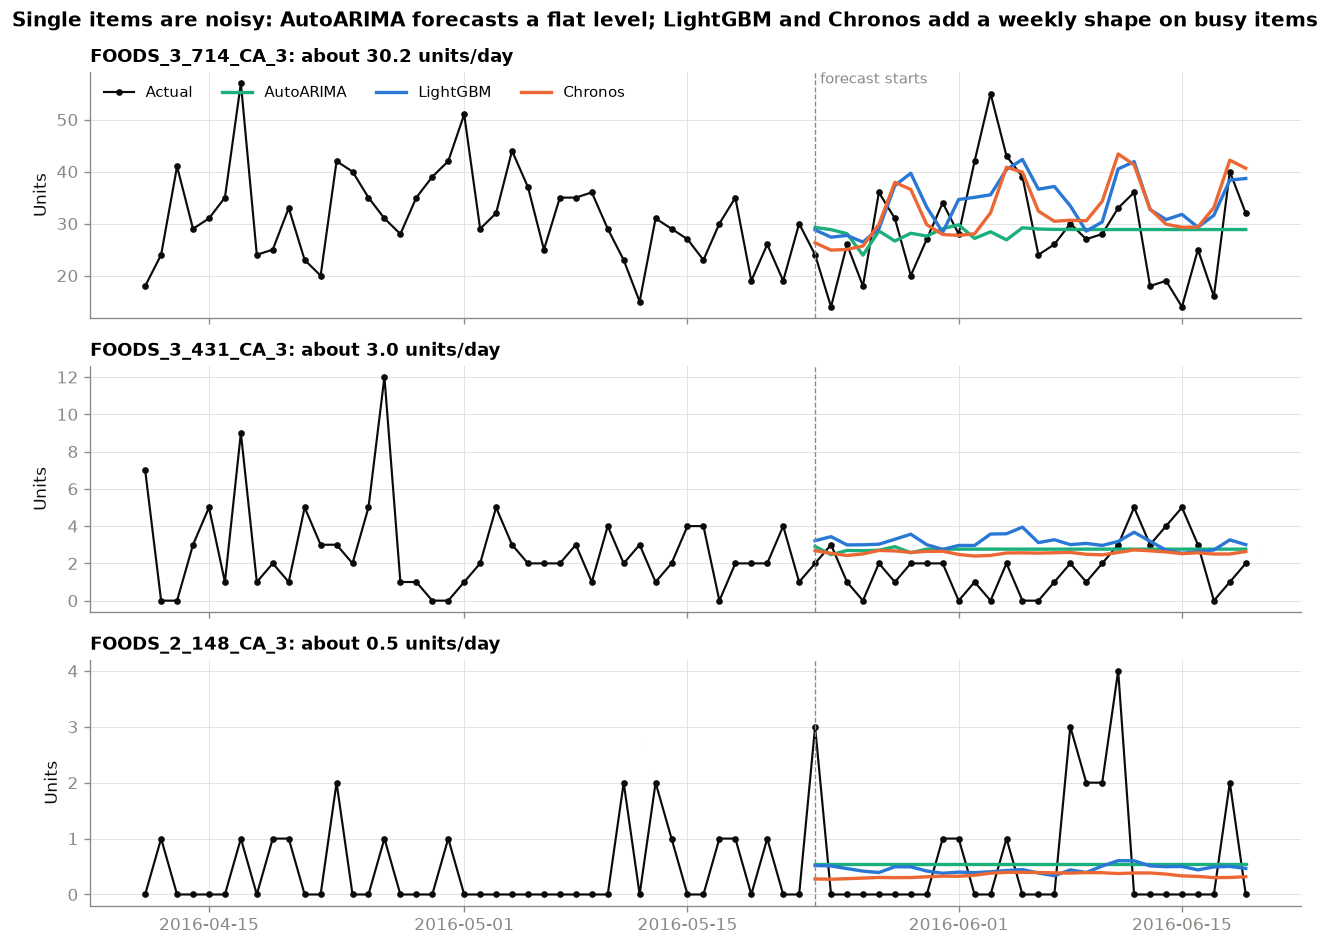

In [8]:
# Example items: high, medium and low sellers in store CA_3
recent = train[train.d_num > 1941 - 90].groupby('unique_id').y.mean()
ca3 = recent[recent.index.str.endswith('CA_3')]
examples = [(ca3 - t).abs().idxmin() for t in (30, 3, 0.5)]
fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
for ax, sid in zip(axes, examples):
    hist = sales[(sales.unique_id == sid) & (sales.d_num > 1941 - 42)]
    fc = joined[joined.unique_id == sid]
    ax.plot(hist.ds, hist.y, color=INK, linewidth=1.3, marker='o', markersize=3, label='Actual')
    for m in MODELS: ax.plot(fc.ds, fc[m], color=COLOR[m], linewidth=2, label=LABEL[m])
    ax.axvline(fc.ds.min(), color=MUTED, linestyle='--', linewidth=0.8)
    ax.set_title(f'{sid}: about {recent[sid]:.1f} units/day', fontsize=11); ax.set_ylabel('Units')
axes[0].legend(ncol=4, loc='upper left', fontsize=9)
axes[0].text(joined.ds.min(), axes[0].get_ylim()[1], ' forecast starts', color=MUTED, fontsize=9, va='top')
fig.suptitle('Single items are noisy: AutoARIMA forecasts a flat level; LightGBM and Chronos add a weekly shape on busy items', x=0.01, ha='left', fontweight='bold', fontsize=12)
save(fig, '07_example_items.png')

## 5. Does accuracy get worse further ahead?

/var/folders/zk/gs87cd3j3397t2rs4ycrr_700000gn/T/ipykernel_76524/2296465013.py:8: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  hz_tot = tw.groupby('week').apply(lambda d: pd.Series({m: (d[m] - d.y).abs().sum() / d.y.sum() * 100 for m in ALL}))


,AutoARIMA,LightGBM,Chronos,Seasonal naive
1,0.810,0.827,0.786,1.053
2,0.928,0.944,0.930,1.159
3,0.920,0.916,0.918,1.153
4,0.926,0.853,0.881,1.151


,AutoARIMA,LightGBM,Chronos,Seasonal naive
week,,,,
1,8.5,6.2,5.9,6.7
2,10.1,4.7,13.9,5.1
3,8.4,1.9,15.1,5.3
4,12.0,3.0,8.5,5.4


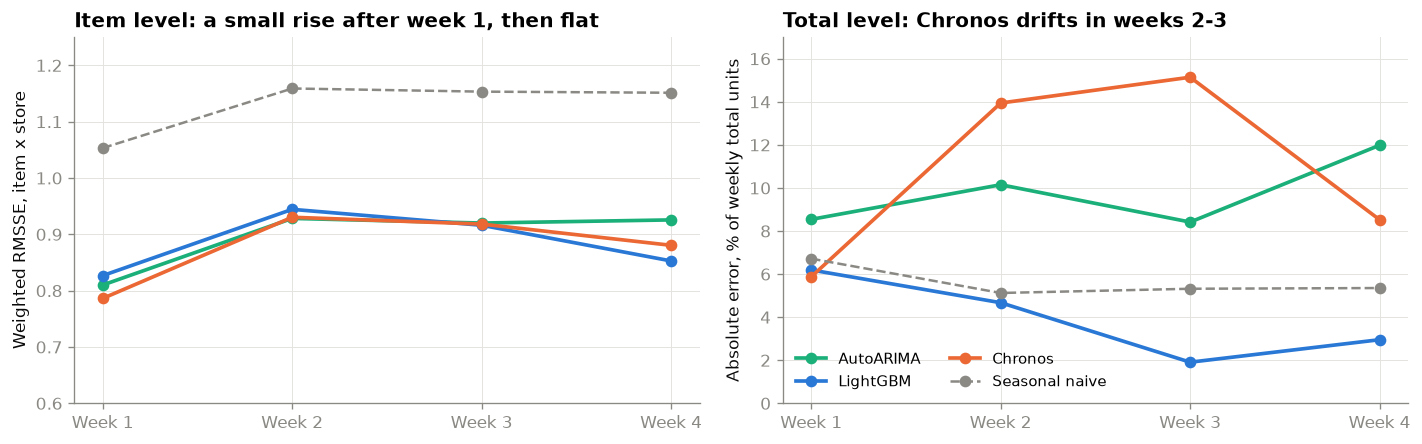

In [9]:
def wrmsse_item(d, m):
    mse = ((d[m] - d.y) ** 2).groupby(d.unique_id).mean()
    info = pd.concat([mse.rename('mse'), d.groupby('unique_id')[['scale', 'w']].first()], axis=1)
    return (np.sqrt(info.mse / info.scale) * info.w).sum() / info.w.sum()

hz = pd.DataFrame({m: [wrmsse_item(g[g.week == k], m) for k in range(1, 5)] for m in ALL}, index=[1, 2, 3, 4])
tw = tot.assign(week=(tot.index - tot.index.min()).days // 7 + 1)
hz_tot = tw.groupby('week').apply(lambda d: pd.Series({m: (d[m] - d.y).abs().sum() / d.y.sum() * 100 for m in ALL}))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for m in ALL:
    st = dict(color=COLOR[m], marker='o', linestyle='--' if m == BENCH else '-', linewidth=1.5 if m == BENCH else 2.2, label=LABEL[m])
    axes[0].plot(hz.index, hz[m], **st); axes[1].plot(hz_tot.index, hz_tot[m], **st)
axes[0].set_title('Item level: a small rise after week 1, then flat'); axes[0].set_ylabel('Weighted RMSSE, item x store')
axes[1].set_title('Total level: Chronos drifts in weeks 2-3'); axes[1].set_ylabel('Absolute error, % of weekly total units')
for ax in axes: ax.set_xticks([1, 2, 3, 4], ['Week 1', 'Week 2', 'Week 3', 'Week 4'])
axes[0].set_ylim(0.6, 1.25); axes[1].set_ylim(0, 17); axes[1].legend(ncol=2, fontsize=9)
save(fig, '08_horizon.png')
display(hz.rename(columns=LABEL).round(3)); display(hz_tot.rename(columns=LABEL).round(1))

## 6. What drives LightGBM

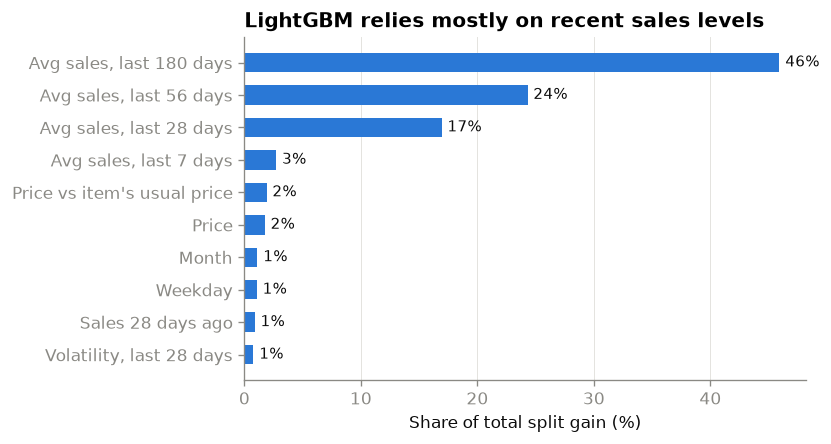

In [10]:
imp = pd.read_parquet(FC/'lgb_importance.parquet').gain
imp = (imp / imp.sum() * 100).head(10).sort_values()
names = {'rmean_180': 'Avg sales, last 180 days', 'rmean_56': 'Avg sales, last 56 days', 'rmean_28': 'Avg sales, last 28 days',
         'rmean_7': 'Avg sales, last 7 days', 'price_rel': 'Price vs item\'s usual price', 'sell_price': 'Price',
         'month': 'Month', 'wday': 'Weekday', 'lag_28': 'Sales 28 days ago', 'rstd_28': 'Volatility, last 28 days'}
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh([names.get(i, i) for i in imp.index], imp.values, color=COLOR['LightGBM'], height=0.6)
for y, v in enumerate(imp.values): ax.text(v + 0.5, y, f'{v:.0f}%', va='center', fontsize=9, color=INK)
ax.grid(axis='y', visible=False)
ax.set_title('LightGBM relies mostly on recent sales levels'); ax.set_xlabel('Share of total split gain (%)')
save(fig, '09_lgb_importance.png')

## 7. Adding Claude, a general-purpose LLM
Claude Opus 5.5 forecast a subset of series (cost: $13.54 for 224 calls): the **12 store x department totals** and **100 randomly sampled items**. It saw the last 365 days as text (date, weekday, holiday, SNAP day, price, units) and returned 28 daily forecasts. It fits no statistical model; it reads the numbers and reasons about them.

Each series was forecast twice: **named** (real dates, Walmart, item and store ids, holiday names) and **blind** (no names or dates, only "day -364 ... +28", weekday and a generic holiday flag). If named beats blind, Claude may be recalling the public M5 data.

**Fair comparison on totals:** Claude forecasts each total directly. Summing 1,437 item forecasts is a harder task, so AutoARIMA, Chronos and seasonal naive were also fitted directly on the 12 totals (`src/models_direct_agg.py`).

,WRMSSE,MAE,MAPE of total (%),Bias (%)
model,,,,
Claude (named),0.579,77.140,3.941,0.557
Claude (blind),0.583,76.119,3.747,-0.628
LightGBM (sum of items),0.628,83.975,4.063,-1.038
Chronos (direct),0.637,82.647,3.811,1.605
AutoARIMA (direct),0.644,82.708,4.998,-0.525
SeasonalNaive (direct),0.739,99.071,5.517,-0.177
AutoARIMA (sum of items),0.900,127.085,9.879,1.745
Chronos (sum of items),0.969,132.818,10.399,-11.011


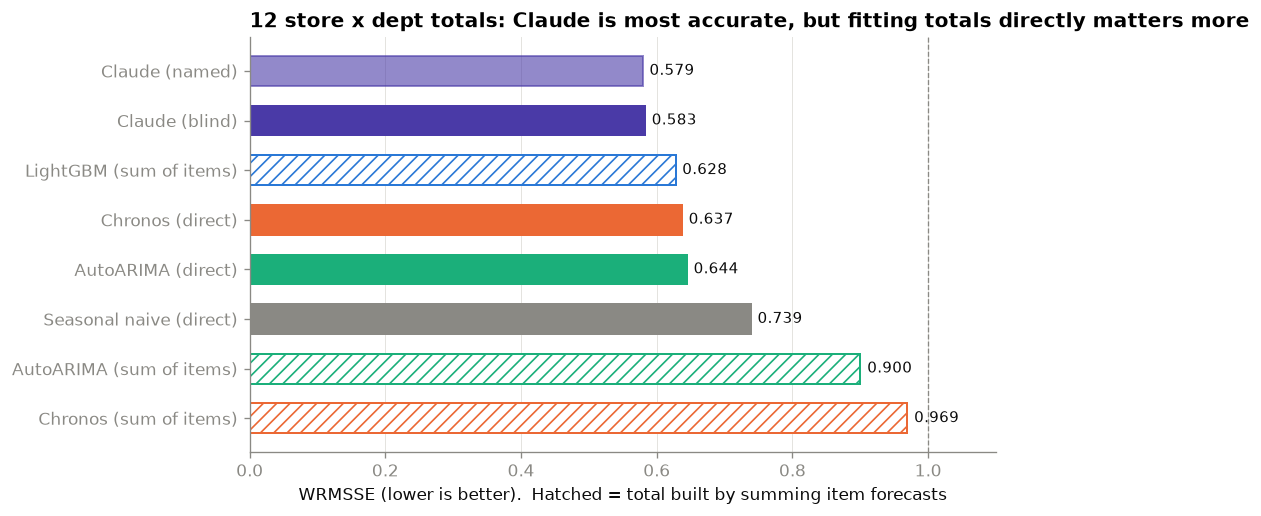

In [11]:
CLAUDE = '#4a3aa7'
COLOR.update({'Claude (blind)': CLAUDE, 'Claude (named)': CLAUDE})
cacc = pd.read_csv(RES/'claude_accuracy.csv')
agg_acc = cacc[cacc.level == 'store x dept'].set_index('model')
item_acc = cacc[cacc.level == 'item x store'].set_index('model')

def family(name):
    return name.split(' (')[0]

order = agg_acc.WRMSSE.drop('SeasonalNaive (sum of items)').sort_values(ascending=False)  # identical to direct by construction
fig, ax = plt.subplots(figsize=(8.5, 4.4))
for y, (name, v) in enumerate(order.items()):
    fam = family(name); col = CLAUDE if fam == 'Claude' else COLOR[fam]
    summed = 'sum of items' in name
    ax.barh(y, v, color='white' if summed else col, edgecolor=col, hatch='///' if summed else None,
            linewidth=1.2, height=0.6, alpha=0.6 if name == 'Claude (named)' else 1)
    ax.text(v + 0.01, y, f'{v:.3f}', va='center', fontsize=9, color=INK)
ax.set_yticks(range(len(order)), [n.replace('SeasonalNaive', 'Seasonal naive') for n in order.index])
ax.axvline(1, color=MUTED, linestyle='--', linewidth=0.8); ax.set_xlim(0, 1.1); ax.grid(axis='y', visible=False)
ax.set_title('12 store x dept totals: Claude is most accurate, but fitting totals directly matters more')
ax.set_xlabel('WRMSSE (lower is better).  Hatched = total built by summing item forecasts')
save(fig, '10_claude_totals.png')
display(agg_acc.drop('SeasonalNaive (sum of items)')[['WRMSSE', 'MAE', 'MAPE of total (%)', 'Bias (%)']].sort_values('WRMSSE').round(3))

,WRMSSE,MAE,Bias (%)
model,,,
AutoARIMA,0.951,1.652,-12.998
Claude (named),0.958,1.674,-16.395
Claude (blind),0.959,1.665,-16.559
Chronos,0.995,1.697,-22.738
LightGBM,1.031,1.836,-20.898
SeasonalNaive,1.138,1.867,-10.339


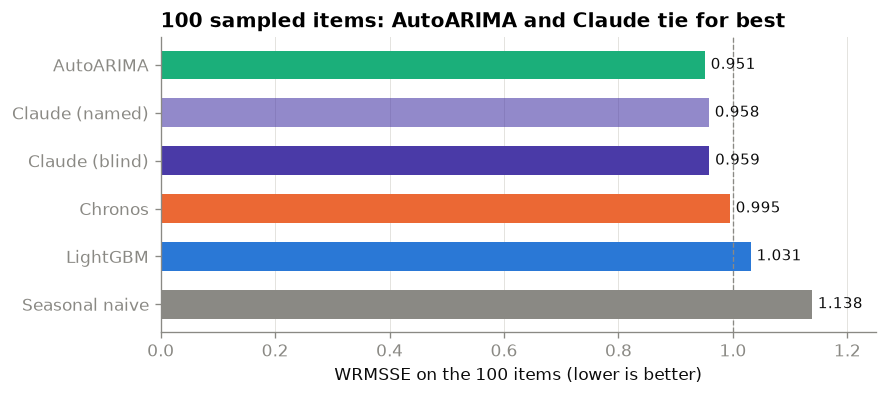

In [12]:
io = item_acc.WRMSSE.sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7.5, 3.4))
for y, (name, v) in enumerate(io.items()):
    fam = family(name); col = CLAUDE if fam == 'Claude' else COLOR[fam]
    ax.barh(y, v, color=col, height=0.6, alpha=0.6 if name == 'Claude (named)' else 1)
    ax.text(v + 0.01, y, f'{v:.3f}', va='center', fontsize=9, color=INK)
ax.set_yticks(range(len(io)), [LABEL.get(n, n) for n in io.index])
ax.axvline(1, color=MUTED, linestyle='--', linewidth=0.8); ax.set_xlim(0, 1.25); ax.grid(axis='y', visible=False)
ax.set_title('100 sampled items: AutoARIMA and Claude tie for best'); ax.set_xlabel('WRMSSE on the 100 items (lower is better)')
save(fig, '11_claude_items.png')
display(item_acc[['WRMSSE', 'MAE', 'Bias (%)']].sort_values('WRMSSE').round(3))

Series where named beats blind: totals 42%, items 43%


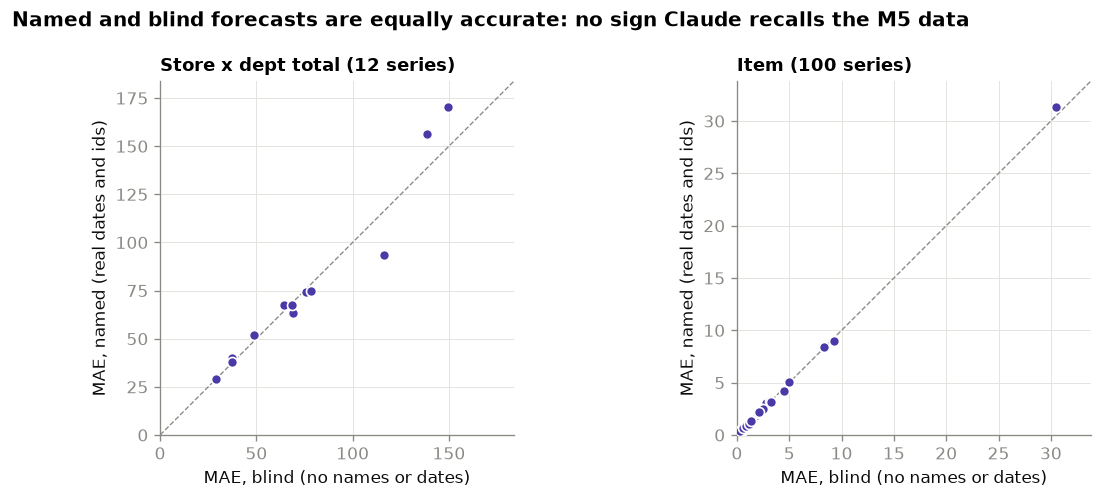

In [13]:
ag = pd.read_parquet(RES/'claude_agg_joined.parquet')
it = pd.read_parquet(RES/'claude_items_joined.parquet')
mae = lambda d, c: (d[c] - d.y).abs().groupby(d.unique_id).mean()
pts = pd.concat([pd.DataFrame({'named': mae(ag, 'Claude (named)'), 'blind': mae(ag, 'Claude (blind)'), 'level': 'Store x dept total'}),
                 pd.DataFrame({'named': mae(it, 'Claude (named)'), 'blind': mae(it, 'Claude (blind)'), 'level': 'Item'})])
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, lvl in zip(axes, ['Store x dept total', 'Item']):
    d = pts[pts.level == lvl]
    lim = [0, d[['named', 'blind']].max().max() * 1.08]
    ax.plot(lim, lim, color=MUTED, linestyle='--', linewidth=0.8)
    ax.scatter(d.blind, d.named, s=36, color=CLAUDE, edgecolor='white', linewidth=1, zorder=3)
    ax.set_xlim(lim); ax.set_ylim(lim); ax.set_aspect('equal')
    ax.set_xlabel('MAE, blind (no names or dates)'); ax.set_ylabel('MAE, named (real dates and ids)')
    ax.set_title(f'{lvl} ({len(d)} series)', fontsize=11)
fig.suptitle('Named and blind forecasts are equally accurate: no sign Claude recalls the M5 data', x=0.01, ha='left', fontweight='bold', fontsize=12)
save(fig, '12_claude_named_vs_blind.png')
print(f"Series where named beats blind: totals {(pts[pts.level != 'Item'].named < pts[pts.level != 'Item'].blind).mean():.0%}, items {(pts[pts.level == 'Item'].named < pts[pts.level == 'Item'].blind).mean():.0%}")

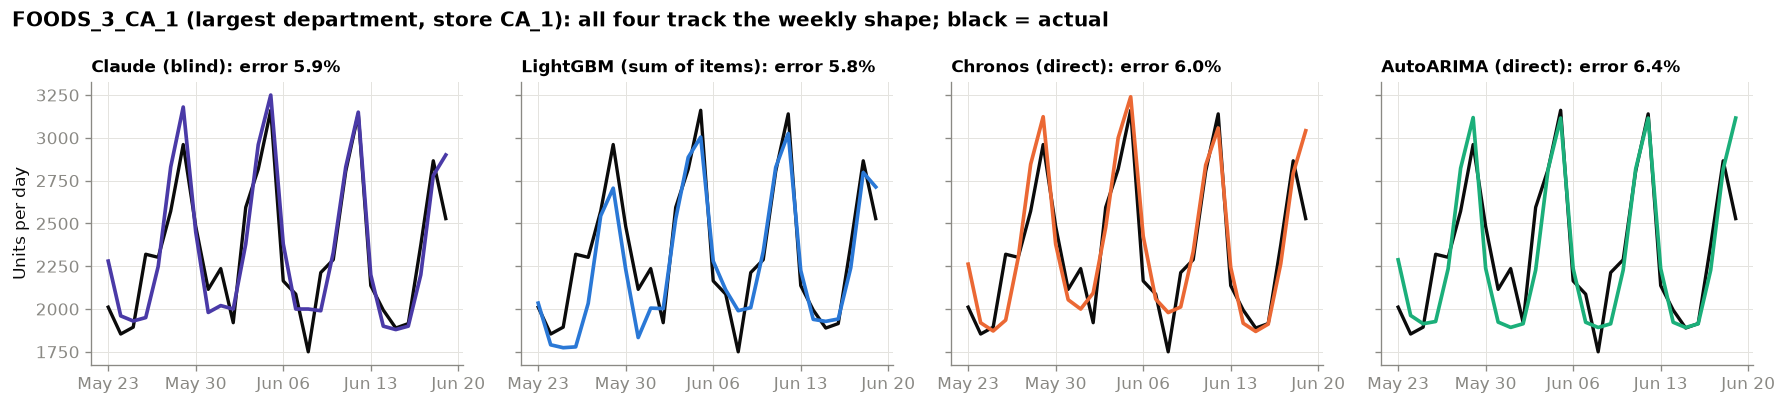

In [14]:
sid = 'FOODS_3_CA_1'
d = ag[ag.unique_id == sid].set_index('ds')
show = [('Claude (blind)', CLAUDE), ('LightGBM (sum of items)', COLOR['LightGBM']),
        ('Chronos (direct)', COLOR['Chronos']), ('AutoARIMA (direct)', COLOR['AutoARIMA'])]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4), sharey=True)
for ax, (col, c) in zip(axes, show):
    err = (d[col] - d.y).abs().mean() / d.y.mean()
    ax.plot(d.index, d.y, color=INK, linewidth=2)
    ax.plot(d.index, d[col], color=c, linewidth=2.2)
    ax.set_title(f'{col}: error {err:.1%}', fontsize=10)
    ax.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=mdates.MO)); ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
axes[0].set_ylabel('Units per day')
fig.suptitle(f'{sid} (largest department, store CA_1): all four track the weekly shape; black = actual', x=0.01, ha='left', fontweight='bold', fontsize=12)
save(fig, '13_claude_example_total.png')

## 8. Computational efficiency
Each model was timed one at a time on the same laptop (10 CPU cores, Apple GPU) for all 5,748 series: fit plus 28-day forecast. Claude was measured on 224 calls (520 s with 6 parallel calls, $13.54) and scaled up to 5,748 series.

,"seconds for 5,748 series",API cost per run ($),measured or estimated
model,,,
Chronos,10.0,0.0,measured
LightGBM,80.0,0.0,measured
AutoARIMA,2322.0,0.0,measured
Claude,13344.0,347.0,estimated


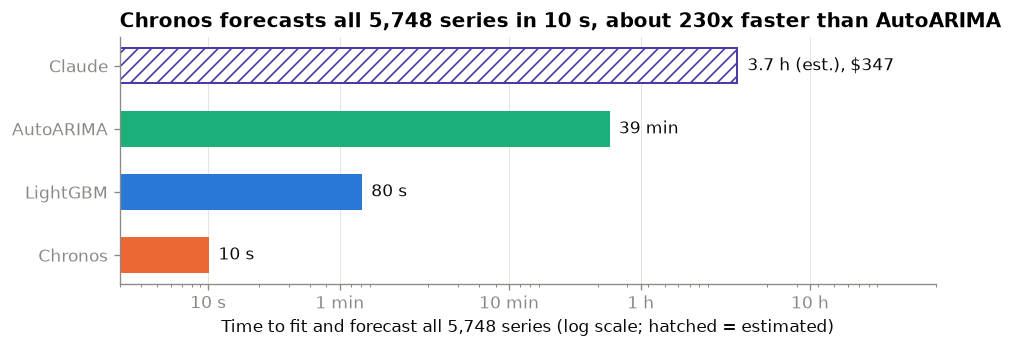

In [15]:
timing = pd.read_csv(RES/'timing.csv').set_index('model')
full = timing.wall_seconds / timing.series * 5748
cost = (timing.api_cost_usd / timing.series * 5748).round(0)
eff = pd.DataFrame({'seconds for 5,748 series': full.round(0), 'API cost per run ($)': cost,
                    'measured or estimated': np.where(timing.series == 5748, 'measured', 'estimated')}).sort_values('seconds for 5,748 series')
display(eff)

fig, ax = plt.subplots(figsize=(8, 3))
for y, (m, sec) in enumerate(eff['seconds for 5,748 series'].items()):
    col = CLAUDE if m == 'Claude' else COLOR[m]
    est = eff.loc[m, 'measured or estimated'] == 'estimated'
    ax.barh(y, sec, color='white' if est else col, edgecolor=col, hatch='///' if est else None, linewidth=1.2, height=0.55)
    label = f'{sec/60:.0f} min' if sec >= 120 else f'{sec:.0f} s'
    if sec >= 3600: label = f'{sec/3600:.1f} h (est.), ${eff.loc[m, "API cost per run ($)"]:.0f}'
    ax.text(sec * 1.15, y, label, va='center', fontsize=10, color=INK)
ax.set_xscale('log'); ax.set_xlim(3, 2e5)
ax.set_yticks(range(len(eff)), eff.index); ax.grid(axis='y', visible=False)
ax.set_xticks([10, 60, 600, 3600, 36000], ['10 s', '1 min', '10 min', '1 h', '10 h'])
ax.set_title('Chronos forecasts all 5,748 series in 10 s, about 230x faster than AutoARIMA')
ax.set_xlabel('Time to fit and forecast all 5,748 series (log scale; hatched = estimated)')
save(fig, '14_efficiency.png')

## 9. Findings
1. **LightGBM is the most accurate item-level model overall** (WRMSSE 0.646 on all 5,748 series, vs 0.892 AutoARIMA and 0.949 Chronos). Its edge comes from aggregate levels: one model trained on all items learns the shared weekly and SNAP patterns.
2. **How totals are built matters as much as the model.** Summing single-item forecasts loses the weekly pattern for AutoARIMA and Chronos (WRMSSE about 0.90-0.97 on the 12 store x dept totals). Fitted directly on the totals, both improve to about 0.64, level with LightGBM.
3. **Claude, a general LLM with no statistical model, was the most accurate on the 12 totals** (WRMSSE 0.58, daily error 3.7%), about 8% better than the next best. On 100 sampled items it tied with AutoARIMA (0.958 vs 0.951).
4. **No evidence of memorization:** Claude's named and blind forecasts are equally accurate, so it is forecasting from the numbers, not recalling the public data.
5. **At single-item level, all models are close.** Each of the three main models is best on roughly a third of series, and all beat the benchmark by about 20%. Daily sales of one item are mostly noise.
6. **Chronos, with zero training, matches the trained models at item level** but runs about 11% low when its item forecasts are summed; fitted directly on totals, that bias disappears.

7. **Efficiency: Chronos is fastest by far** (10 s for all series, no training), then LightGBM (80 s), AutoARIMA (39 min). Claude would take about 3.7 hours and $347 per full run.

Caveats: one 28-day test window; Claude was run on 112 of the 5,748 series, and its forecasts can vary slightly between runs. A rolling backtest would show whether the rankings are stable.